# Análisis exploratorio de datos

El análisis sigue dos bloques: el **EDA general** (objetivo, faltantes, rangos físicos y desplazamiento entre
particiones) y el **EDA específico de series de tiempo** (descomposición, estacionariedad, autocorrelación,
heterocedasticidad, series múltiples y valores extremos). Cada análisis termina con tres frases:
**decisión de preprocesamiento**, **impacto en la arquitectura** y **riesgo**.

In [1]:
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, signal
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.diagnostic import het_arch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

warnings.simplefilter("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv("datos/panel_multivariado_causal.csv", dtype={"CodigoEstacion": str}, parse_dates=["hora"])
df["anio"] = df.hora.dt.year
print(f"{len(df):,} estación-horas | {df.CodigoEstacion.nunique()} estaciones | {df.hora.min()} a {df.hora.max()}")

1,308,726 estación-horas | 76 estaciones | 2020-01-01 00:00:00 a 2025-12-31 23:00:00


## EDA general

### Variable objetivo: velocidad del viento

media 1.93 m/s | desviación 1.50 | asimetría 1.52 | curtosis en exceso 2.65
calmas (v = 0): 0.51% | percentil 99: 6.93 | máximo 23.97 m/s


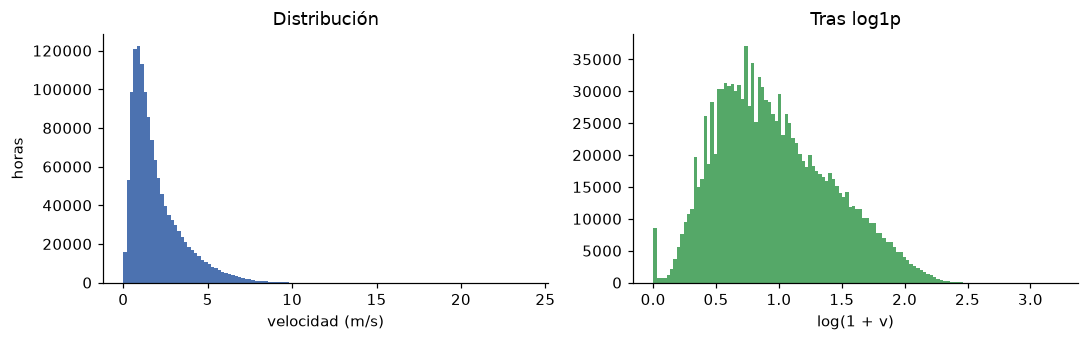

In [2]:
v = df.vel
print(f"media {v.mean():.2f} m/s | desviación {v.std():.2f} | asimetría {stats.skew(v):.2f} | "
      f"curtosis en exceso {stats.kurtosis(v):.2f}")
print(f"calmas (v = 0): {(v == 0).mean():.2%} | percentil 99: {v.quantile(.99):.2f} | máximo {v.max():.2f} m/s")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(v, bins=120, color="#4C72B0"); ax[0].set(xlabel="velocidad (m/s)", ylabel="horas", title="Distribución")
ax[1].hist(np.log1p(v), bins=120, color="#55A868"); ax[1].set(xlabel="log(1 + v)", title="Tras log1p")
plt.tight_layout(); plt.show()

La velocidad es asimétrica a la derecha (asimetría ≈ 1.5) con colas moderadas, como es típico del viento
(distribución de tipo Weibull). Las calmas exactas son pocas (≈ 0.5 %), así que no hace falta un modelo de dos partes.

- **Decisión:** se modela la velocidad en m/s, sin transformar, porque la métrica primaria (RMSE) se declaró en
  esas unidades; las entradas sí se estandarizan.
- **Impacto en la arquitectura:** salida lineal de una neurona y pérdida MSE, coherente con el RMSE.
- **Riesgo:** la cola derecha pesa mucho en el MSE; si el piloto muestra que las ráfagas dominan el error, se
  probará la pérdida de Huber como variante (no como modelo principal).

### Faltantes y su mecanismo

Faltantes por variable (%):
vel         0.00
dir_sin     3.12
dir_cos     3.12
temp       10.84
pres       18.34

Cobertura horaria media de las estaciones activas, por año:
anio
2020    0.59
2021    0.48
2022    0.42
2023    0.31
2024    0.31
2025    0.62


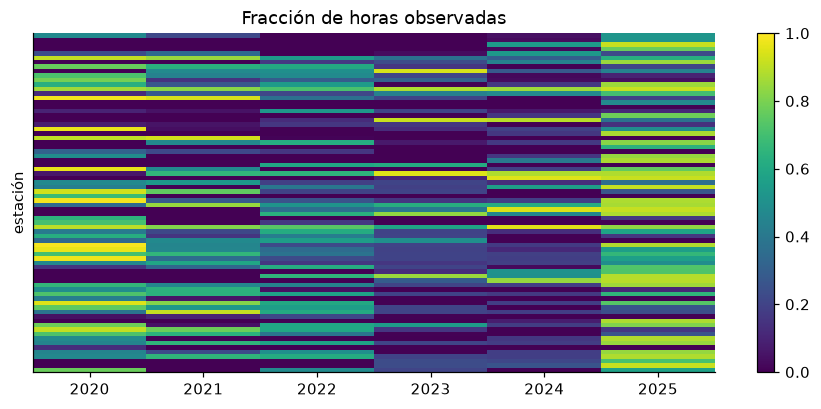

In [3]:
cols = ["vel", "dir_sin", "dir_cos", "temp", "pres"]
print("Faltantes por variable (%):"); print((df[cols].isna().mean() * 100).round(2).to_string())
cob = df.groupby(["CodigoEstacion", "anio"]).size().unstack() / 8760
print("\nCobertura horaria media de las estaciones activas, por año:"); print(cob.mean().round(2).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(cob.fillna(0).values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set(xticks=range(cob.shape[1]), xticklabels=cob.columns, ylabel="estación", title="Fracción de horas observadas")
ax.set_yticks([]); plt.colorbar(im, ax=ax); plt.show()

La velocidad nunca falta *dentro* del panel (las filas existen porque hubo medición), pero la cobertura temporal es
incompleta: en promedio cada estación reporta entre el 30 % y el 60 % de las horas del año. El faltante de interés
está en la **presión** (18 %) y la **temperatura** (11 %). Para saber si se pueden descartar filas sin sesgo se
compara quién tiene presión y quién no:

In [4]:
est = df.groupby("CodigoEstacion").agg(altitud=("altitud", "first"), vel_media=("vel", "mean"),
                                       pres_falta=("pres", lambda s: s.isna().mean()))
sin_p, con_p = est[est.pres_falta > .5], est[est.pres_falta <= .5]
print(f"Estaciones sin presión (> 50 % faltante): {len(sin_p)} | nunca la midieron: {(est.pres_falta == 1).sum()}")
print(f"Altitud media: sin presión {sin_p.altitud.mean():.0f} m vs con presión {con_p.altitud.mean():.0f} m")
a, b = df.loc[df.pres.isna(), "vel"], df.loc[df.pres.notna(), "vel"]
print(f"Velocidad media cuando falta la presión {a.mean():.2f} m/s vs cuando está {b.mean():.2f} m/s "
      f"(Mann-Whitney p = {stats.mannwhitneyu(a.sample(20000, random_state=0), b.sample(20000, random_state=0)).pvalue:.1e})")

Estaciones sin presión (> 50 % faltante): 14 | nunca la midieron: 10
Altitud media: sin presión 518 m vs con presión 179 m


Velocidad media cuando falta la presión 1.65 m/s vs cuando está 1.99 m/s (Mann-Whitney p = 4.7e-94)


El faltante de presión **no es MCAR**: se concentra en estaciones concretas (diez nunca tuvieron barómetro), más
altas y con menos viento. Depende de una variable observada (la estación), lo que corresponde a **MAR**. Quitar las
filas sin presión no sería neutro: se perderían justamente las estaciones de montaña y de viento débil.

- **Decisión:** se **descarta la presión** como entrada y se conservan velocidad, dirección (seno y coseno) y
  temperatura. Los huecos de hasta 3 h se rellenan con el último valor (solo mira al pasado); las ventanas con
  huecos mayores se descartan.
- **Impacto en la arquitectura:** la entrada pasa de 5 a 4 canales ($d = 4$); el número de ventanas de
  entrenamiento sube de 313 935 a 387 770 y de 50 a 60 estaciones.
- **Riesgo:** la presión aporta información sinóptica (frentes, ondas tropicales); su ausencia puede costar algo de
  precisión. La configuración con presión se conserva en `configs/datos_con_presion.json` como análisis de
  sensibilidad.

### Rango físico, duplicados y sensores dañados

In [5]:
print(f"Duplicados estación-hora: {df.duplicated(['CodigoEstacion', 'hora']).sum()}")
print(f"Temperatura: {df.temp.min()} a {df.temp.max()} °C | presión: {df.pres.min()} a {df.pres.max()} hPa")
g = df.groupby("CodigoEstacion").vel
sosp = pd.DataFrame({"horas": g.size(), "media": g.mean(), "ceros_%": g.apply(lambda s: (s == 0).mean() * 100),
                     "valores_distintos": g.nunique()}).sort_values("ceros_%", ascending=False).head(4)
print(sosp.round(3))

Duplicados estación-hora: 0
Temperatura: 3.3 a 45.0 °C | presión: 774.2 a 1024.8 hPa


                horas  media  ceros_%  valores_distintos
CodigoEstacion                                          
1501500054       3225  0.000   99.845                  6
0029065501       4228  0.483   18.401               3438
0028045501      16441  0.830    9.926              14742
0015035020      14051  1.698    3.950                853


No hay duplicados ni valores imposibles (las presiones bajas, ≈ 774 hPa, corresponden a estaciones por encima de
2 000 m). La estación **1501500054** tiene el 99.8 % de las horas en cero y solo 6 valores distintos: es un
anemómetro bloqueado, no calma real.

- **Decisión:** se excluye la estación 1501500054 (`excluir_estaciones` en la configuración).
- **Impacto en la arquitectura:** ninguno en la forma de la red; evita que el modelo aprenda a predecir cero.
- **Riesgo:** otros sensores pueden fallar de forma menos evidente (por ejemplo, valores congelados unas horas);
  el relleno limitado a 3 h reduce ese riesgo pero no lo elimina.

### Desplazamiento entre particiones

In [6]:
df = df[df.CodigoEstacion != "1501500054"].copy()
part = np.select([df.anio <= 2023, df.anio == 2024], ["entrenamiento", "validación"], "prueba")
df["particion"] = part
print(df.groupby("particion").agg(horas=("vel", "size"), estaciones=("CodigoEstacion", "nunique"),
                                  vel_media=("vel", "mean"), vel_sd=("vel", "std")).round(3))
for x, y in [("entrenamiento", "validación"), ("validación", "prueba")]:
    r = stats.ks_2samp(df.vel[df.particion == x], df.vel[df.particion == y])
    print(f"KS {x} vs {y}: D = {r.statistic:.3f}, p = {r.pvalue:.1e}")

                horas  estaciones  vel_media  vel_sd
particion                                           
entrenamiento  801781          66      1.979   1.522
prueba         356156          66      1.853   1.458
validación     147564          54      1.874   1.437
KS entrenamiento vs validación: D = 0.039, p = 3.6e-167


KS validación vs prueba: D = 0.021, p = 3.0e-42


Con cientos de miles de horas cualquier diferencia es «significativa»; lo que importa es el tamaño: $D \approx 0.02$
a $0.04$, es decir, las funciones de distribución difieren en menos de 4 puntos porcentuales. Como prueba más
exigente se entrena un **clasificador adversarial** que intenta distinguir 2024 de 2025 con las variables
meteorológicas y la hora del día (sin la estación ni el mes, que delatarían el año trivialmente):

In [7]:
d = df[df.anio.isin([2024, 2025])].dropna(subset=["temp"]).sample(60000, random_state=0)
Xa = np.column_stack([d.vel, d.dir_sin.fillna(0), d.dir_cos.fillna(0), d.temp, d.hora.dt.hour])
auc = cross_val_score(HistGradientBoostingClassifier(max_iter=200), Xa, d.anio == 2025, cv=5, scoring="roc_auc")
print(f"AUC adversarial 2024 vs 2025: {auc.mean():.3f} ± {auc.std():.3f}")
for f in [["vel"], ["vel", "temp"]]:
    i = [0] if f == ["vel"] else [0, 3]
    a_ = cross_val_score(HistGradientBoostingClassifier(max_iter=200), Xa[:, i], d.anio == 2025, cv=5, scoring="roc_auc")
    print(f"  solo {' + '.join(f)}: AUC {a_.mean():.3f}")

AUC adversarial 2024 vs 2025: 0.743 ± 0.006


  solo vel: AUC 0.527


  solo vel + temp: AUC 0.547


Un AUC de ≈ 0.74 es un desplazamiento claro, pero la velocidad sola apenas distingue los años (≈ 0.53). La señal
aparece al combinar dirección, temperatura y hora, que juntas delatan la **época del año**. La razón está en la
cobertura mensual:

In [8]:
m = df[df.anio.isin([2024, 2025])].groupby(["anio", df.hora.dt.month]).size().unstack()
print("Fracción de las horas de cada año que cae en cada mes:")
print(m.div(m.sum(axis=1), axis=0).round(2).to_string())

Fracción de las horas de cada año que cae en cada mes:
hora    1     2     3     4     5     6     7     8     9     10    11    12
anio                                                                        
2024  0.04  0.04  0.06  0.05  0.05  0.05  0.07  0.08  0.09  0.08  0.20  0.21
2025  0.09  0.01  0.07  0.07  0.07  0.09  0.10  0.09  0.09  0.10  0.11  0.12


En 2024 el **41 % de las horas está en noviembre y diciembre**, mientras que 2025 está repartido de forma pareja.
Es decir, el desplazamiento no es tanto un cambio de clima como un **cambio en la composición estacional** de los
datos disponibles (además, la red pasó de 54 a 66 estaciones).

- **Decisión:** se mantiene la partición cronológica (entrenamiento ≤ 2023, validación 2024, prueba 2025), con
  escalado ajustado solo con entrenamiento y **embargo** de $L + 24$ horas: una ventana solo pertenece a un
  conjunto si toda su extensión cae dentro de él.
- **Impacto en la arquitectura:** la validación de 2024 se usa para la parada temprana y para elegir
  hiperparámetros; 2025 queda congelado.
- **Riesgo:** la validación está cargada hacia fin de año (temporada de vientos alisios más fuertes en el Caribe),
  así que el error de validación no representa un año completo. La diferencia entre validación y prueba debe
  leerse como desplazamiento, no como sobreajuste, y se reportará el error de prueba por mes.

## EDA específico de series de tiempo

Se usa como estación representativa la de más horas observadas, el aeropuerto Almirante Padilla de Riohacha
(0015065180), y su tramo continuo más largo, para que la autocorrelación no mezcle horas separadas por huecos.

In [9]:
cod = df.groupby("CodigoEstacion").size().idxmax()
s = df[df.CodigoEstacion == cod].set_index("hora").vel.asfreq("h")
ok = s.notna().to_numpy().astype(int)
cambios = np.flatnonzero(np.diff(np.r_[0, ok, 0]))
ini, fin = max(zip(cambios[::2], cambios[1::2]), key=lambda t: t[1] - t[0])
b = s.iloc[ini:fin]
print(f"Estación {cod}: tramo continuo de {len(b)} h, de {b.index[0]} a {b.index[-1]}")

Estación 0015065180: tramo continuo de 1704 h, de 2025-03-07 00:00:00 a 2025-05-16 23:00:00


### Descomposición STL y ciclo diario

Varianza explicada: estacional diaria 66% | tendencia 24% | residuo 13%


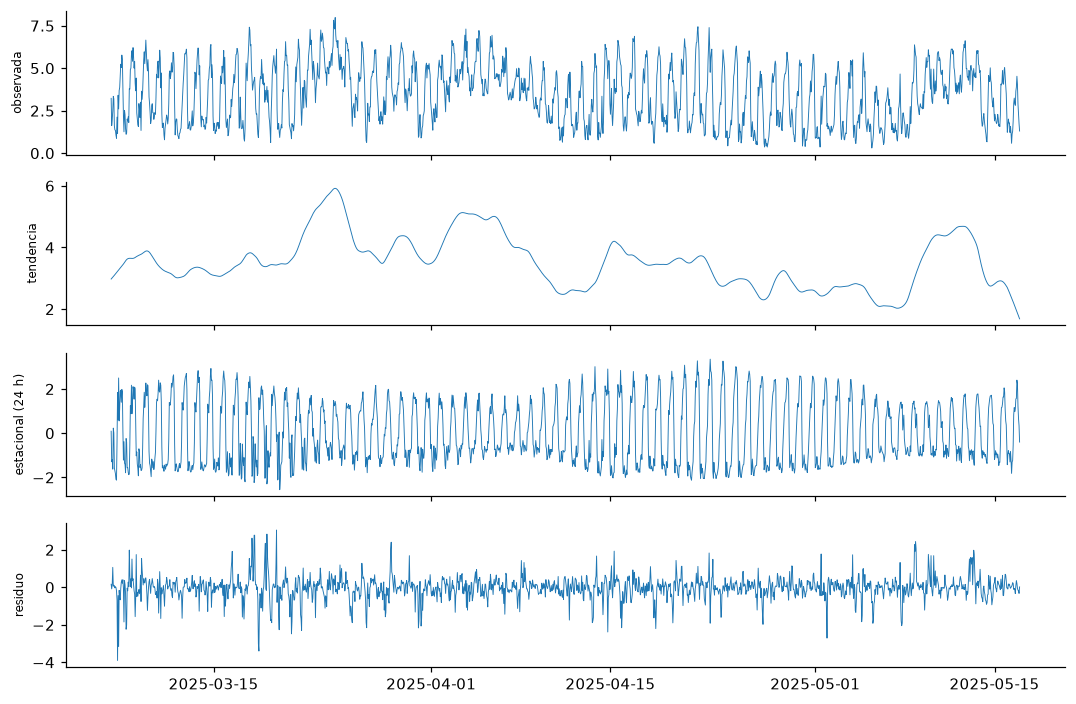

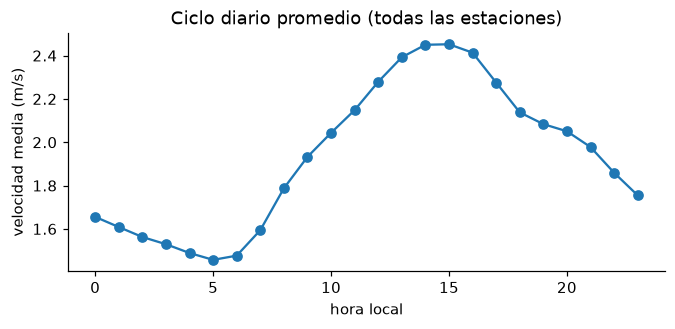

In [10]:
st = STL(b, period=24, robust=True).fit()
var = np.var(b)
print(f"Varianza explicada: estacional diaria {np.var(st.seasonal) / var:.0%} | tendencia {np.var(st.trend) / var:.0%} "
      f"| residuo {np.var(st.resid) / var:.0%}")
fig, ax = plt.subplots(4, 1, figsize=(10, 6.5), sharex=True)
for a_, (n, x) in zip(ax, [("observada", b), ("tendencia", st.trend), ("estacional (24 h)", st.seasonal),
                           ("residuo", st.resid)]):
    a_.plot(x.index, x.values, lw=.6); a_.set_ylabel(n, fontsize=8)
plt.tight_layout(); plt.show()
perfil = df.groupby(df.hora.dt.hour).vel.mean()
plt.figure(figsize=(7, 2.8)); plt.plot(perfil.index, perfil.values, "o-")
plt.xlabel("hora local"); plt.ylabel("velocidad media (m/s)"); plt.title("Ciclo diario promedio (todas las estaciones)")
plt.show()

El ciclo diario domina: explica cerca de dos tercios de la varianza del tramo, con el máximo a media tarde
(calentamiento y brisa marina en la costa Caribe) y el mínimo de madrugada.

- **Decisión:** no se agregan variables de calendario explícitas; la ventana de entrada contiene varios ciclos
  completos y la red puede inferir la fase. Como el horizonte es exactamente 24 h, la **persistencia**
  $\hat v_{t+24} = v_t$ ya captura el ciclo y es el baseline obligatorio.
- **Impacto en la arquitectura:** favorece modelos que vean la ventana completa (MLP, CNN con filtros que abarquen
  la escala de horas, LSTM).
- **Riesgo:** un modelo que solo reproduzca el ciclo empatará con la persistencia; la mejora real debe venir de
  anticipar las desviaciones del ciclo.

### Autocorrelación, periodograma y longitud de la ventana

ACF en rezagos 1, 24, 48, 72, 168, 336: [0.901 0.776 0.657 0.575 0.446 0.389]
PACF en rezagos 1, 2, 23, 24, 25: [ 0.901 -0.219  0.162  0.015 -0.116] | banda ±0.047
Periodos con más potencia (h): [np.float64(24.0), np.float64(1704.0), np.float64(284.0), np.float64(12.0), np.float64(568.0), np.float64(426.0)]


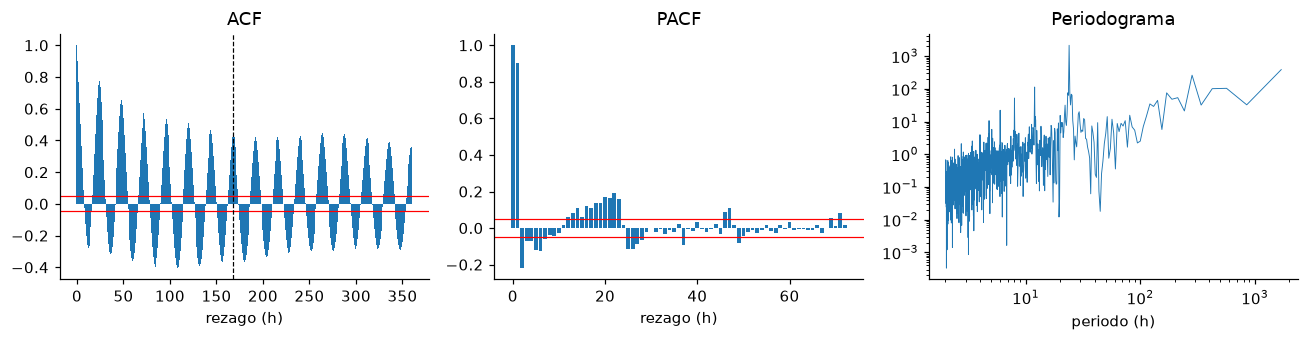

In [11]:
r_acf = acf(b, nlags=360, fft=True)
r_pacf = pacf(b, nlags=72)
banda = 1.96 / np.sqrt(len(b))
print("ACF en rezagos 1, 24, 48, 72, 168, 336:", np.round(r_acf[[1, 24, 48, 72, 168, 336]], 3))
print("PACF en rezagos 1, 2, 23, 24, 25:", np.round(r_pacf[[1, 2, 23, 24, 25]], 3), f"| banda ±{banda:.3f}")
f, P = signal.periodogram(b - b.mean())
top = [round(1 / f[k], 1) for k in np.argsort(P)[::-1][:6] if f[k] > 0]
print("Periodos con más potencia (h):", top)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].bar(range(361), r_acf, width=1); ax[0].axhline(banda, c="r", lw=.8); ax[0].axhline(-banda, c="r", lw=.8)
ax[0].axvline(168, ls="--", c="k", lw=.8); ax[0].set(title="ACF", xlabel="rezago (h)")
ax[1].bar(range(73), r_pacf, width=.8); ax[1].axhline(banda, c="r", lw=.8); ax[1].axhline(-banda, c="r", lw=.8)
ax[1].set(title="PACF", xlabel="rezago (h)")
ax[2].semilogy(1 / f[1:], P[1:], lw=.6); ax[2].set(xscale="log", title="Periodograma", xlabel="periodo (h)")
plt.tight_layout(); plt.show()

La ACF oscila con periodo de 24 h (el ciclo diario) y su envolvente decae lentamente: sigue en ≈ 0.45 a las 168 h,
muy por encima de la banda de significancia. La PACF tiene picos en los rezagos 1 y 2 y otra vez alrededor del 24,
y el periodograma confirma 24 h (y su armónico de 12 h) como periodos dominantes.

- **Decisión:** ventana de entrada $L = 168$ h (7 días): contiene siete ciclos diarios y llega hasta donde la ACF
  todavía es claramente significativa, sin alargar en exceso el entrenamiento de la LSTM.
- **Impacto en la arquitectura:** la entrada es un tensor de $168 \times 4$; para el MLP equivale a 672 entradas.
  La CNN necesita un campo receptivo de al menos 24 h para capturar el ciclo.
- **Riesgo:** dependencias más largas (sinópticas, de semanas) quedan fuera de la ventana; ampliar $L$ se deja
  para el Entregable 2.

### Estacionariedad: ADF y KPSS por estación

In [12]:
filas = []
for c, g in df.groupby("CodigoEstacion"):
    x = g.set_index("hora").vel.asfreq("h").interpolate(limit=3).dropna()
    if len(x) < 2000:
        continue
    x = x.iloc[-8000:]
    p_adf = adfuller(x, autolag="AIC")[1]
    p_kpss = kpss(x, regression="c", nlags="auto")[1]
    p_arch = het_arch(x - x.rolling(24, min_periods=1).mean(), nlags=24)[1]
    filas.append((c, p_adf, p_kpss, p_arch))
pr = pd.DataFrame(filas, columns=["estacion", "p_adf", "p_kpss", "p_arch"])
pr["escenario"] = np.select(
    [(pr.p_adf < .05) & (pr.p_kpss >= .05), (pr.p_adf >= .05) & (pr.p_kpss < .05), (pr.p_adf < .05) & (pr.p_kpss < .05)],
    ["1. estacionaria (ambas coinciden)", "2. raíz unitaria (ambas coinciden)",
     "3. ADF rechaza raíz y KPSS rechaza estacionariedad"], "4. ninguna rechaza")
print(f"{len(pr)} estaciones con al menos 2 000 h"); print(pr.escenario.value_counts().to_string())

73 estaciones con al menos 2 000 h
escenario
3. ADF rechaza raíz y KPSS rechaza estacionariedad    69
1. estacionaria (ambas coinciden)                      4


Los cuatro escenarios posibles son: (1) ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad → serie
estacionaria; (2) lo contrario → raíz unitaria, hay que diferenciar; (3) ambas rechazan → la serie no tiene raíz
unitaria pero tampoco es estacionaria alrededor de una media fija (típico de estacionalidad fuerte o cambios de
nivel); (4) ninguna rechaza → evidencia insuficiente. Casi todas las estaciones caen en el **escenario 3**: el
viento revierte a su media (no es un paseo aleatorio), pero esa media cambia con el ciclo diario y las épocas del año.

- **Decisión:** **no se diferencia** la serie (no hay raíz unitaria); se estandariza con la media y la desviación
  del entrenamiento y la ventana de 7 días aporta el nivel reciente.
- **Impacto en la arquitectura:** la red recibe niveles, no diferencias, y predice niveles directamente.
- **Riesgo:** los cambios de nivel entre años (ver el desplazamiento) pueden sesgar el pronóstico; se revisará el
  sesgo medio de los residuos en el benchmark.

### Heterocedasticidad (prueba ARCH)

In [13]:
print(f"Estaciones con efecto ARCH (p < 0.05): {(pr.p_arch < .05).sum()} de {len(pr)}")

Estaciones con efecto ARCH (p < 0.05): 73 de 73


La varianza del viento no es constante: hay rachas de alta variabilidad (lluvias, frentes) y periodos tranquilos.

- **Decisión:** se mantiene la pérdida MSE por coherencia con el RMSE declarado, y la de Huber queda como variante.
- **Impacto en la arquitectura:** los errores grandes se concentrarán en los periodos volátiles; las pruebas de
  Diebold–Mariano usan la corrección de Harvey–Leybourne–Newbold, robusta a esta autocorrelación y
  heterocedasticidad.
- **Riesgo:** los intervalos de confianza que asumen varianza constante quedarían demasiado estrechos; por eso se
  usa bootstrap por bloques.

### Series múltiples: ¿modelo global o por estación?

Media por estación: 0.48 a 5.73 m/s | desviación: 0.29 a 2.31
Kruskal-Wallis entre estaciones p = 0.0e+00 | Levene p = 0.0e+00


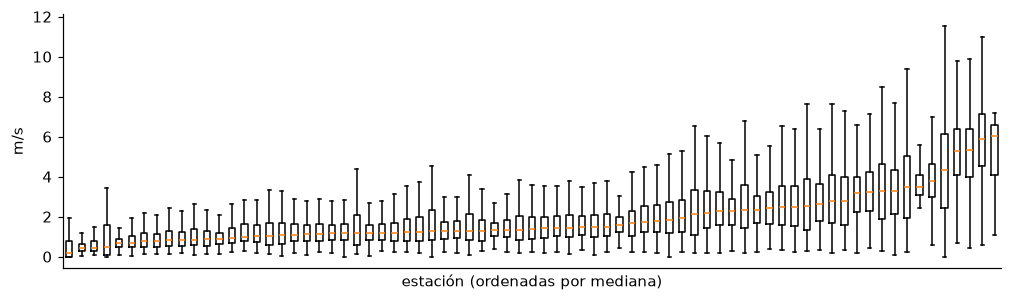

In [14]:
g = df.groupby("CodigoEstacion").vel
print(f"Media por estación: {g.mean().min():.2f} a {g.mean().max():.2f} m/s | "
      f"desviación: {g.std().min():.2f} a {g.std().max():.2f}")
muestras = [x.sample(min(len(x), 2000), random_state=0) for _, x in g]
print(f"Kruskal-Wallis entre estaciones p = {stats.kruskal(*muestras).pvalue:.1e} | "
      f"Levene p = {stats.levene(*muestras).pvalue:.1e}")
orden = g.median().sort_values().index
plt.figure(figsize=(11, 3)); plt.boxplot([g.get_group(c).values for c in orden], showfliers=False)
plt.xticks([]); plt.xlabel("estación (ordenadas por mediana)"); plt.ylabel("m/s"); plt.show()

Las estaciones difieren mucho en nivel (de 0.5 a 5.7 m/s de media) y en variabilidad. Aun así, entrenar una red por
estación dejaría a muchas con pocos miles de ventanas, insuficientes para una red profunda.

- **Decisión:** **un modelo global** para todas las estaciones, entrenado con las ventanas de todas, con escalado
  global ajustado en entrenamiento. Como la ventana incluye la historia de la propia estación, la red ve su nivel.
- **Impacto en la arquitectura:** más datos por parámetro; las tres redes comparten exactamente la misma entrada.
- **Riesgo:** las estaciones de viento fuerte (La Guajira) dominan el MSE; se reportará el error por estación y la
  estación es la unidad de independencia en las pruebas.

### Valores extremos

In [15]:
med = g.transform("median"); mad = g.transform(lambda x: (x - x.median()).abs().median())
z = (df.vel - med) / (1.4826 * mad)
print(f"Horas con |z robusto| > 6: {(z.abs() > 6).sum():,} ({(z.abs() > 6).mean():.3%})")
print(f"Velocidades > 20 m/s: {(df.vel > 20).sum()}")

Horas con |z robusto| > 6: 2,032 (0.156%)
Velocidades > 20 m/s: 6


- **Decisión:** no se eliminan los extremos: son ráfagas físicamente posibles y precisamente lo que interesa
  anticipar. Solo se excluyó el sensor bloqueado.
- **Impacto en la arquitectura:** la salida no se acota; se evaluará el error en el percentil 95 de velocidad como
  análisis complementario.
- **Riesgo:** pocos valores extremos pueden inflar el RMSE de un modelo; se revisará su efecto comparando el RMSE
  con y sin esas horas.

## Resumen de decisiones

| Hallazgo | Decisión |
|---|---|
| Presión faltante en 18 %, concentrada en estaciones altas (MAR) | Se descarta la presión; $d = 4$ entradas |
| Sensor bloqueado en la estación 1501500054 | Se excluye |
| Ciclo diario explica ≈ 2/3 de la varianza | Baseline de persistencia a 24 h obligatorio |
| ACF significativa hasta 168 h | Ventana $L = 168$ h |
| Escenario 3 de ADF/KPSS (sin raíz unitaria, media cambiante) | No se diferencia; se estandariza |
| Efecto ARCH en todas las estaciones | MSE con Huber como variante; DM con corrección HLN |
| Estaciones heterogéneas pero con pocos datos cada una | Modelo global; la estación es la unidad de independencia |
| Leve desplazamiento 2024 → 2025 | Partición cronológica con embargo; 2025 congelado |